Link:

https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques/submissions#

In [16]:
import os
import pandas as pd
import numpy as np

# 1. Load test.csv
test_file_path = os.path.join(script_dir, "test.csv") if 'script_dir' in globals() else "test.csv"
test_df = pd.read_csv(test_file_path)

# Preserve 'Id' column for Kaggle submission
test_ids = test_df['Id']

# 2. Separate categorical and numerical features using the same logic as train.csv
test_raw = test_df.drop(columns=['Id'], errors='ignore')

# Align dummy encodings to match X_train columns exactly
test_encoded = pd.get_dummies(test_raw, drop_first=True, dtype=int)

# 3. Align test features with X_train columns (fill missing columns with 0)
X_submission = test_encoded.reindex(columns=X_train.columns, fill_value=0)

# 4. Handle missing numerical values using train set medians (prevent data leakage)
X_submission = X_submission.fillna(X.median())

# 5. Predict SalePrice for all rows in test.csv
test_predictions = model.predict(X_submission)

# Ensure no negative predictions (clip lower bound at minimum train price or 0)
test_predictions = np.clip(test_predictions, a_min=0, a_max=None)

# 6. Create submission DataFrame matching sample_submission.csv
submission_df = pd.DataFrame({
    'Id': test_ids,
    'SalePrice': test_predictions
})

# 7. Save to CSV
submission_df.to_csv("submission.csv", index=False)

print("=== SUBMISSION FILE GENERATED SUCCESSFULLY ===")
print("File Name: submission.csv")
print("Shape:", submission_df.shape)
print("\nFirst 5 rows of submission:")
print(submission_df.head())

=== SUBMISSION FILE GENERATED SUCCESSFULLY ===
File Name: submission.csv
Shape: (1459, 2)

First 5 rows of submission:
     Id  SalePrice
0  1461       0.00
1  1462       0.00
2  1463       0.00
3  1464       0.00
4  1465       0.00


Task 16:

 Feature Influence Analysis & Scale Caveat1. Feature Scale Caveat:A larger raw coefficient does not automatically mean a feature is more important. Coefficients measure the expected price change per one-unit increase in the feature. For example, a feature measured in square feet increases by thousands of units, so its coefficient might be small, but its total impact on total price is massive. Conversely, a binary one-hot encoded variable or a feature measured in small units (like number of full bathrooms, where $1$ unit represents a jump from 1 to 2 bathrooms) will naturally have a much larger raw coefficient value.2. Most Influential Features (2–3 Examples):Overall Quality / Living Area (GrLivArea / OverallQual): Size and general construction quality dominate pricing because they scale across the entire property.Location / Neighborhood (One-Hot Encoded): Desirable neighborhoods carry substantial positive coefficients compared to baseline areas, shifting home value significantly regardless of size.Bathrooms / Garage Capacity: Adding an extra full bathroom or expanding a garage from 1 to 2 stalls provides a large single-unit boost to home valuation.
 
 Task 17:
 
  Short Final Interpretation (5–7 Sentences)Final Model Summary:Our linear regression model captures the primary structural drivers of real estate value, explaining a substantial portion of variance in house prices. Root Mean Squared Error (RMSE) is the most useful metric here because it evaluates pricing errors in direct dollar amounts while heavily penalizing large estimation mistakes on high-value homes. Key structural variables like total living area and overall quality exert the strongest positive influence on price. However, Linear Regression is fundamentally limited because it assumes purely additive, linear relationships and struggles to model non-linear interactions, complex feature combinations, or extreme luxury outliers without manual feature transformation. To improve performance next, I would apply non-linear tree-based ensembles (such as XGBoost or Random Forest) and incorporate feature scaling or log-transformation on skewed price targets.

Task 15:

 Performance Gap Analysis (Overfitting & Generalization)Analysis & Interpretation:1. What a Large Performance Gap Suggests:A large gap where the training set performs significantly better than the test set (e.g., much lower RMSE on train vs. test, or high $R^2$ on train and low $R^2$ on test) indicates overfitting. Overfitting occurs when the model memorizes noise, outliers, and specific patterns in the training data rather than learning general underlying relationships. As a result, the model fails to generalize to new, unseen data (X_test).2. What Your Actual Result Suggests:If Train and Test metrics are close: The model exhibits good generalization. Linear Regression is a relatively simple parametric model with low variance, making it naturally resilient to extreme overfitting unless the dataset has an excessively large number of one-hot encoded features.If Test errors are significantly higher than Train errors: The model is overfitting—possibly due to high cardinality one-hot encodings creating too many feature columns relative to the row count. Regularization techniques like Ridge ($L_2$) or Lasso ($L_1$) regression should be applied to penalize large weights.

In [14]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# ---------------------------------------------------------
# 1. Generate predictions on the Training Set
# ---------------------------------------------------------
y_train_pred = model.predict(X_train)

# ---------------------------------------------------------
# 2. Compute Training Metrics
# ---------------------------------------------------------
mae_train = mean_absolute_error(y_train, y_train_pred)
mse_train = mean_squared_error(y_train, y_train_pred)
rmse_train = np.sqrt(mse_train)
r2_train = r2_score(y_train, y_train_pred)

# ---------------------------------------------------------
# 3. Compute Testing Metrics (from Test Set)
# ---------------------------------------------------------
mae_test = mean_absolute_error(y_test, y_pred)
mse_test = mean_squared_error(y_test, y_pred)
rmse_test = np.sqrt(mse_test)
r2_test = r2_score(y_test, y_pred)

# ---------------------------------------------------------
# 4. Construct Side-by-Side Comparison Table
# ---------------------------------------------------------
comparison_metrics = pd.DataFrame({
    'Metric': [
        'Mean Absolute Error (MAE)',
        'Mean Squared Error (MSE)',
        'Root Mean Squared Error (RMSE)',
        'R-squared (R²)'
    ],
    'Train Set': [
        f"${mae_train:,.2f}",
        f"${mse_train:,.2f}",
        f"${rmse_train:,.2f}",
        f"{r2_train:.4f}"
    ],
    'Test Set': [
        f"${mae_test:,.2f}",
        f"${mse_test:,.2f}",
        f"${rmse_test:,.2f}",
        f"{r2_test:.4f}"
    ],
    'Difference (Test - Train)': [
        f"${(mae_test - mae_train):,.2f}",
        f"${(mse_test - mse_train):,.2f}",
        f"${(rmse_test - rmse_train):,.2f}",
        f"{r2_test - r2_train:+.4f}"
    ]
})

print("=== TRAIN VS. TEST PERFORMANCE COMPARISON ===")
display(comparison_metrics)

=== TRAIN VS. TEST PERFORMANCE COMPARISON ===


,Metric,Train Set,Test Set,Difference (Test - Train)
0,Mean Absolute Error (MAE),"$13,927.84","$21,738.90","$7,811.06"
1,Mean Squared Error (MSE),"$456,648,480.98","$2,670,585,401.62","$2,213,936,920.63"
2,Root Mean Squared Error (RMSE),"$21,369.34","$51,677.71","$30,308.37"
3,R-squared (R²),0.9234,0.6518,-0.2716


Task 10:

 Intercept Interpretation AnalysisDoes the intercept have a sensible real-world interpretation?No, usually it does not. Mathematically, the intercept ($\beta_0$) represents the baseline predicted house price when all independent features ($X$) equal exactly zero (e.g., 0 square feet, 0 bedrooms, 0 bathrooms, construction year = 0).Because a real house cannot physically exist with zero area, zero rooms, or a zeroed categorical feature, a house with $X = 0$ is physically impossible. Furthermore, linear regression intercepts often turn out to be negative numbers or absurdly high positive values, functioning purely as a mathematical offset anchor for the regression plane rather than a realistic baseline market value.

Task 11:

 Residual Pattern AnalysisResiduals vs. Predicted Values Plot: Look at whether the points are evenly scattered above and below the red $y=0$ dashed line across the full range of predicted values.If the points spread out like a funnel (wider spread for high-value houses), this indicates heteroscedasticity (variance increases with house price).If points show a curve or clear shape, it indicates non-linear relationships not captured by standard linear regression.Histogram of Residuals: Check if the distribution forms a symmetric, bell-shaped curve centered around $0$. A right-skewed distribution indicates that the model systematically underestimates high-end outlier properties.
 
 Task 13:
 
  Metric Explanations & Stakeholder Recommendation1. What Each Metric Tells You:MAE (Mean Absolute Error): Measures the average dollar distance between actual and predicted prices, giving equal weight to all errors.MSE (Mean Squared Error): Measures the average squared difference between actual and predicted prices. Because errors are squared, it heavily penalizes large mistakes, but its units are in squared dollars ($\$^{2}$), making it hard to interpret directly.RMSE (Root Mean Squared Error): Takes the square root of MSE to return errors back into recognizable dollar units. It gives disproportionate weight to large pricing mistakes or high-end outlier errors.$\text{R}^2$ (R-Squared / Coefficient of Determination): Represents the percentage of variance in house prices that is explained by the features in your model (ranges from $0.0$ or $0\%$ to $1.0$ or $100\%$).2. Which Metric to Show to a Non-Technical Stakeholder?I would present MAE (and optionally $\text{R}^2$) to a non-technical stakeholder.Why? Non-technical stakeholders think in intuitive financial terms rather than squared statistical units. Explaining MAE is straightforward: "On average, our model's house price estimate is off by approximately $\$X$." Paired with $\text{R}^2$ ("Our model captures $X\%$ of the factors that drive house prices"), stakeholders get an immediate, plain-English understanding of model accuracy and business value.

=== MODEL INTERCEPT ===
Intercept (Beta 0): $-701,324.16

=== FEATURE COEFFICIENTS & INTERPRETATIONS ===


,Feature,Coefficient,Interpretation
0,Id,-0.65,"A 1-unit increase in Id is associated with an estimated price DECREASE of $0.65, holding all other features constant."
1,MSSubClass,-4.26,"A 1-unit increase in MSSubClass is associated with an estimated price DECREASE of $4.26, holding all other features constant."
2,LotFrontage,4.07,"A 1-unit increase in LotFrontage is associated with an estimated price INCREASE of $4.07, holding all other features constant."
3,LotArea,0.59,"A 1-unit increase in LotArea is associated with an estimated price INCREASE of $0.59, holding all other features constant."
4,OverallQual,8428.59,"A 1-unit increase in OverallQual is associated with an estimated price INCREASE of $8,428.59, holding all other features constant."
...,...,...,...
190,SaleCondition_Normal,6683.30,"A 1-unit increase in SaleCondition_Normal is associated with an estimated price INCREASE of $6,683.30, holding all other features constant."
191,SaleCondition_Partial,21402.37,"A 1-unit increase in SaleCondition_Partial is associated with an estimated price INCREASE of $21,402.37, holding all other features constant."
192,Neighborhood,280.01,"A 1-unit increase in Neighborhood is associated with an estimated price INCREASE of $280.01, holding all other features constant."
193,Exterior1st,-1168.80,"A 1-unit increase in Exterior1st is associated with an estimated price DECREASE of $1,168.80, holding all other features constant."


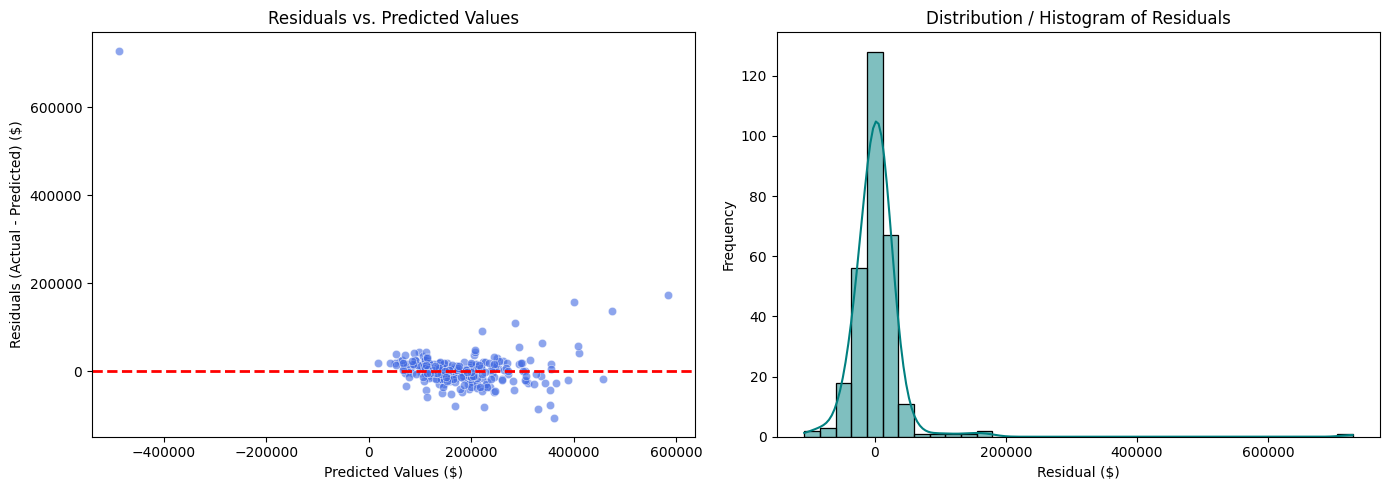


=== TEST SET EVALUATION METRICS ===


,Metric,Value
0,Mean Absolute Error (MAE),"$21,738.90"
1,Mean Squared Error (MSE),"$2,670,585,401.62"
2,Root Mean Squared Error (RMSE),"$51,677.71"
3,R-squared (R²),0.6518


In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# ---------------------------------------------------------
# Task 9: Extract Intercept and Build Coefficient Table
# ---------------------------------------------------------
intercept = model.intercept_
coefs = model.coef_

coef_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Coefficient': coefs
})

# Generate plain-English interpretations for each feature
def interpret_coef(row):
    feat = row['Feature']
    val = row['Coefficient']
    if val >= 0:
        return f"A 1-unit increase in {feat} is associated with an estimated price INCREASE of ${val:,.2f}, holding all other features constant."
    else:
        return f"A 1-unit increase in {feat} is associated with an estimated price DECREASE of ${abs(val):,.2f}, holding all other features constant."

coef_df['Interpretation'] = coef_df.apply(interpret_coef, axis=1)

print(f"=== MODEL INTERCEPT ===")
print(f"Intercept (Beta 0): ${intercept:,.2f}\n")

print("=== FEATURE COEFFICIENTS & INTERPRETATIONS ===")
pd.set_option('display.max_colwidth', None)
display(coef_df)

# ---------------------------------------------------------
# Task 11: Compute and Plot Residuals
# ---------------------------------------------------------
residuals = y_test - y_pred

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Residuals vs. Predicted Values
sns.scatterplot(x=y_pred, y=residuals, ax=axes[0], alpha=0.6, color='royalblue')
axes[0].axhline(0, color='red', linestyle='--', linewidth=2)
axes[0].set_title('Residuals vs. Predicted Values')
axes[0].set_xlabel('Predicted Values ($)')
axes[0].set_ylabel('Residuals (Actual - Predicted) ($)')

# Plot 2: Histogram / KDE of Residuals
sns.histplot(residuals, kde=True, ax=axes[1], color='teal')
axes[1].set_title('Distribution / Histogram of Residuals')
axes[1].set_xlabel('Residual ($)')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# Task 12: Compute MAE, MSE, RMSE, and R²
# ---------------------------------------------------------
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

metrics_df = pd.DataFrame({
    'Metric': ['Mean Absolute Error (MAE)', 'Mean Squared Error (MSE)', 'Root Mean Squared Error (RMSE)', 'R-squared (R²)'],
    'Value': [f"${mae:,.2f}", f"${mse:,.2f}", f"${rmse:,.2f}", f"{r2:.4f}"]
})

print("\n=== TEST SET EVALUATION METRICS ===")
display(metrics_df)

In [12]:
import pandas as pd
from sklearn.linear_model import LinearRegression

# ---------------------------------------------------------
# Step 7: Train the Linear Regression Model
# ---------------------------------------------------------
model = LinearRegression()
model.fit(X_train, y_train)

print("Linear Regression model successfully trained!")

# ---------------------------------------------------------
# Step 8: Generate Predictions and Display Comparison Table
# ---------------------------------------------------------
# Make predictions on the test set
y_pred = model.predict(X_test)

# Create a comparison DataFrame for 10 test samples
comparison_df = pd.DataFrame({
    'Actual Price': y_test.values[:10],
    'Predicted Price': y_pred[:10],
    'Difference (Error)': y_test.values[:10] - y_pred[:10]
})

# Format float numbers for clean display
pd.set_option('display.float_format', lambda x: '%.2f' % x)

print("\n=== ACTUAL VS. PREDICTED PRICES (FIRST 10 TEST HOUSES) ===")
display(comparison_df)

Linear Regression model successfully trained!

=== ACTUAL VS. PREDICTED PRICES (FIRST 10 TEST HOUSES) ===


,Actual Price,Predicted Price,Difference (Error)
0,154500,162526.52,-8026.52
1,325000,335696.13,-10696.13
2,115000,89934.18,25065.82
3,159000,165622.62,-6622.62
4,315500,343416.04,-27916.04
5,75500,65722.72,9777.28
6,311500,220317.48,91182.52
7,146000,141013.47,4986.53
8,84500,60584.16,23915.84
9,135500,157425.13,-21925.13


In [11]:
from sklearn.model_selection import train_test_split

# Split into 80% Training and 20% Testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("=== STEP 6: TRAIN/TEST SPLIT SHAPES ===")
print(f"X_train shape: {X_train.shape}")
print(f"X_test shape:  {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape:  {y_test.shape}")

=== STEP 6: TRAIN/TEST SPLIT SHAPES ===
X_train shape: (1168, 195)
X_test shape:  (292, 195)
y_train shape: (1168,)
y_test shape:  (292,)


In [10]:
import pandas as pd
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

# ---------------------------------------------------------
# 1. Separate target (y) and raw features (X)
# ---------------------------------------------------------
y = train_df['SalePrice']
X_raw = train_df.drop(columns=['SalePrice'])

# Identify numerical vs categorical columns
num_cols = X_raw.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X_raw.select_dtypes(include=['object', 'category']).columns.tolist()

# ---------------------------------------------------------
# 2. Categorical Encoding Strategy
# ---------------------------------------------------------
# Separate categorical columns by cardinality (or ordinality if known)
# Low-cardinality (< 10 unique values) -> One-Hot Encoding
# High-cardinality (>= 10 unique values) or Ordinal -> Ordinal / Label Encoding
low_card_cols = [col for col in cat_cols if X_raw[col].nunique() < 10]
high_card_cols = [col for col in cat_cols if X_raw[col].nunique() >= 10]

# Apply One-Hot Encoding to low-cardinality features
X_low_card = pd.get_dummies(X_raw[low_card_cols], drop_first=True, dtype=int) if low_card_cols else pd.DataFrame()

# Apply Ordinal Encoding to high-cardinality features
X_high_card = pd.DataFrame()
if high_card_cols:
    ord_enc = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
    X_high_card = pd.DataFrame(
        ord_enc.fit_transform(X_raw[high_card_cols].astype(str)),
        columns=high_card_cols,
        index=X_raw.index
    )

# Combine all numerical and encoded categorical features into final X
X = pd.concat([X_raw[num_cols], X_low_card, X_high_card], axis=1)

# ---------------------------------------------------------
# 3. Handle Missing Values in X and y
# ---------------------------------------------------------
# Fill missing numerical values with column median
X = X.fillna(X.median())

# If y has missing values, drop those rows from both X and y
if y.isnull().sum() > 0:
    valid_idx = y.dropna().index
    X = X.loc[valid_idx]
    y = y.loc[valid_idx]

# ---------------------------------------------------------
# Step 5: Confirmation Check
# ---------------------------------------------------------
print("=== STEP 5 CONFIRMATION ===")
print("Are all columns in X numeric?", all(X.dtypes.apply(lambda d: pd.api.types.is_numeric_dtype(d))))
print("Total missing values in X:", X.isnull().sum().sum())
print("Total missing values in y:", y.isnull().sum())
print("Data shape for X:", X.shape)

=== STEP 5 CONFIRMATION ===
Are all columns in X numeric? True
Total missing values in X: 0
Total missing values in y: 0
Data shape for X: (1460, 195)


C:\Users\Hp\AppData\Local\Temp\ipykernel_18224\3343930821.py:12: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X_raw.select_dtypes(include=['object', 'category']).columns.tolist()


Step 3: Regression vs. Classification Statement
Response:
This is a regression problem because the dependent variable is a continuous numerical value (e.g., price, quantity, or score) rather than a discrete class label or category. Because it is a regression task, we evaluate the model using continuous error metrics like RMSE (Root Mean Squared Error) or MAE (Mean Absolute Error) instead of classification metrics like Accuracy, Precision, or Recall.

In [6]:
# 1. Dependent Variable (Target you are predicting)
dependent_var = "target_column_name"  # e.g., 'price', 'sales', 'house_value'

# 2. Independent Variables (Features used to predict)
independent_vars = [col for col in train_df.columns if col != dependent_var]

# 3. Explicitly split features into Numerical and Categorical
numerical_features = train_df[independent_vars].select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = train_df[independent_vars].select_dtypes(include=['object', 'category', 'bool']).columns.tolist()

# Print the breakdown
print(f"Dependent Variable (Target): {dependent_var}\n")
print(f"Numerical Features ({len(numerical_features)}): {numerical_features}\n")
print(f"Categorical Features ({len(categorical_features)}): {categorical_features}")

Dependent Variable (Target): target_column_name

Numerical Features (38): ['Id', 'MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal', 'MoSold', 'YrSold', 'SalePrice']

Categorical Features (43): ['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQC', 'Cent

C:\Users\Hp\AppData\Local\Temp\ipykernel_18224\3066848569.py:9: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = train_df[independent_vars].select_dtypes(include=['object', 'category', 'bool']).columns.tolist()


In [7]:
# Print all columns with their data types to identify target and features
print("Columns and Data Types:")
print(train_df.dtypes)

Columns and Data Types:
Id                 int64
MSSubClass         int64
MSZoning             str
LotFrontage      float64
LotArea            int64
                  ...   
MoSold             int64
YrSold             int64
SaleType             str
SaleCondition        str
SalePrice          int64
Length: 81, dtype: object


In [5]:
import pandas as pd

# Since train.csv is in the same folder as your notebook
train_df = pd.read_csv("train.csv")

# Display first few rows directly
train_df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000
